# Japanese Word Familiarity Prediction with XGBoost

This experiment predicts the 「知っている」 word familiarity score from WLSP-familiarity. After filtering entries, the dataset contains 100,373 rows. Each word is represented by a LaBSE embedding and three features: character length, hiragana count, and kanji count.

The target is transformed with log(max_familiarity + 1 - familiarity). This reverses its ordering: higher raw model predictions correspond to lower familiarity. The application must invert the transformation before displaying familiarity scores or sorting them in descending order.

[Dataset](https://github.com/masayu-a/WLSP-familiarity) (`bunruidb-fam.csv`)

Libraries:

```text
matplotlib==3.10.9
matplotlib-inline==0.2.1
pandas==3.0.2
scikit-learn==1.8.0
scipy==1.17.1
torch==2.11.0+cu126
xgboost==3.2.0
tqdm==4.67.3
numpy==2.4.4
sentence-transformers==5.4.1
```

In [1]:
import re
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from scipy.stats import spearmanr
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer
from scipy.stats import spearmanr
import xgboost as xgb
import torch
from sentence_transformers import SentenceTransformer

c:\Users\AORUS 16X\Documents\Sekai LoRA\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('bunruidb-fam.csv', encoding='utf-8-sig')
pd.set_option('display.max_columns', None)

print(df.shape)
df.head()

(101067, 26)


,レコードＩＤ番号,見出し番号,レコード種別,類,部門,中項目,分類項目,分類番号,段落番号,小段落番号,語番号,見出し,見出し本体,読み,逆読み,知っている,書く,読む,話す,聞く,生産,受容,書記,音声,生産-受容,書記-音声
0,1,1,A,体,関係,事柄,事柄,1.1,1,1,1,者（もの）,者,もの,のも,1.466420,0.569324,0.621675,0.559391,0.733162,1.128715,1.354837,1.190999,1.292553,-0.226122,-0.101554
1,2,2,A,体,関係,事柄,事柄,1.1,1,1,2,の,の,の,の,0.681905,0.900859,0.998970,0.944396,0.956736,1.845255,1.955706,1.899829,1.901132,-0.110451,-0.001303
2,3,3,A,体,関係,事柄,事柄,1.1,1,1,3,分（ぶん）,分,ぶん,んぶ,1.041595,0.548134,0.562989,0.399093,0.543941,0.947227,1.106930,1.111123,0.943035,-0.159703,0.168089
3,4,4,A,体,関係,事柄,事柄,1.1,1,1,4,やつ,やつ,やつ,つや,1.243173,0.416562,0.578044,0.557592,0.661892,0.974154,1.239936,0.994606,1.219484,-0.265782,-0.224878
4,5,5,A,体,関係,事柄,事柄,1.1,1,2,1,−こ［椀〜］,−こ,こ,こ,-0.397368,-1.149494,-1.134444,-1.147348,-1.133315,-2.296842,-2.267758,-2.283938,-2.280663,-0.029084,-0.003275


In [3]:
df = df[['見出し本体','知っている']]

df['見出し本体'] = df['見出し本体'].apply(lambda x: np.nan if x.startswith('−') else x)
df = df.dropna()
df

,見出し本体,知っている
0,者,1.466420
1,の,0.681905
2,分,1.041595
3,やつ,1.243173
5,対象,1.853723
...,...,...
101062,すいっちょ,-0.963837
101063,みんみん,0.609637
101064,じーじー,0.452110
101065,かなかな,-0.707855


In [4]:
df['単語の長さ'] = df['見出し本体'].apply(lambda x: len(x))
df['ひらがな数'] = df['見出し本体'].apply(lambda x: sum([len(sym) for sym in re.findall(r'[\u3040-\u309F]+', x)]))
df['漢字数'] = df['見出し本体'].apply(lambda x: sum([len(sym) for sym in re.findall(r'[\u4E00-\u9FFF]+', x)]))
df

,見出し本体,知っている,単語の長さ,ひらがな数,漢字数
0,者,1.466420,1,0,1
1,の,0.681905,1,1,0
2,分,1.041595,1,0,1
3,やつ,1.243173,2,2,0
5,対象,1.853723,2,0,2
...,...,...,...,...,...
101062,すいっちょ,-0.963837,5,5,0
101063,みんみん,0.609637,4,4,0
101064,じーじー,0.452110,4,2,0
101065,かなかな,-0.707855,4,4,0


In [5]:
df.describe()

,知っている,単語の長さ,ひらがな数,漢字数
count,100373.000000,100373.000000,100373.000000,100373.000000
mean,0.984609,3.336027,1.182858,1.742471
std,0.898286,1.573694,1.607199,1.031940
min,-1.782747,1.000000,0.000000,0.000000
25%,0.385060,2.000000,0.000000,1.000000
50%,1.339801,3.000000,0.000000,2.000000
75%,1.692027,4.000000,2.000000,2.000000
max,2.356011,26.000000,17.000000,12.000000


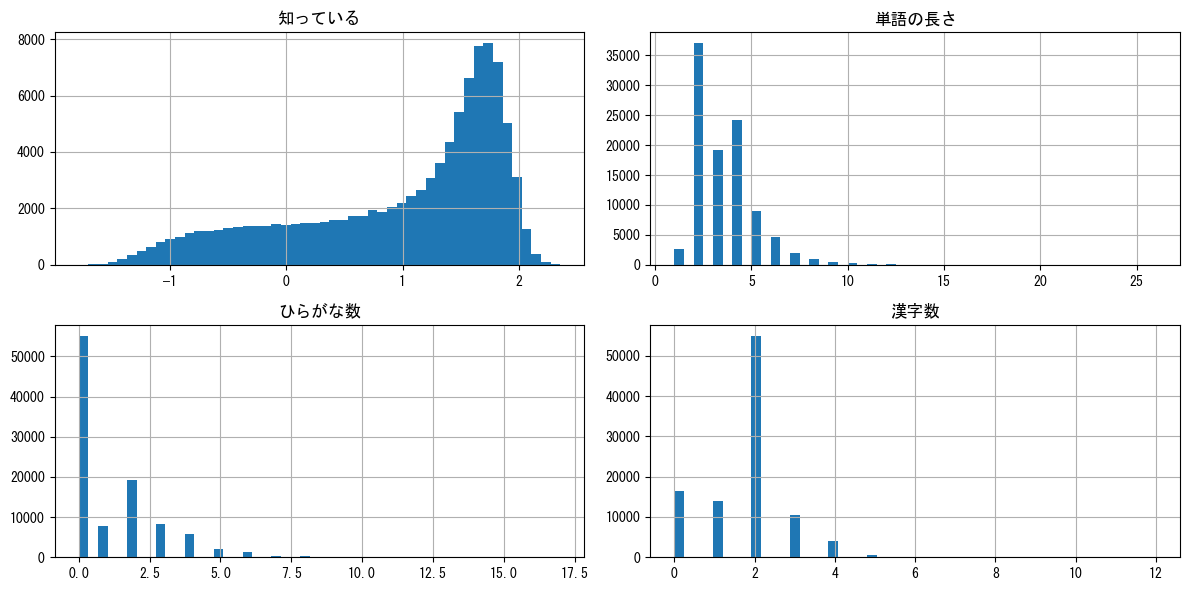

In [6]:
plt.rcParams['font.family'] = 'MS Gothic' 

fig, axes = plt.subplots(figsize=(12, 6), ncols=2, nrows=2)

df['知っている'].hist(bins=50, ax=axes[0][0])
axes[0][0].set_title('知っている')

df['単語の長さ'].hist(bins=50, ax=axes[0][1])
axes[0][1].set_title('単語の長さ')

df['ひらがな数'].hist(bins=50, ax=axes[1][0])
axes[1][0].set_title('ひらがな数')

df['漢字数'].hist(bins=50, ax=axes[1][1])
axes[1][1].set_title('漢字数')
plt.tight_layout()
plt.show()

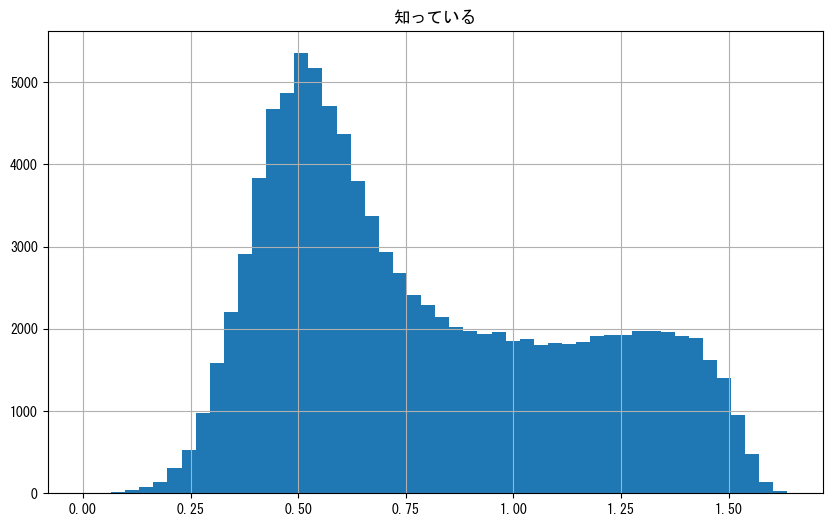

In [7]:
max_familiarity = df['知っている'].max()
df['知っている'] = df['知っている'].apply(lambda x: np.log(max_familiarity + 1 - x))

fig, ax = plt.subplots(figsize=(10, 6))
df['知っている'].hist(bins=50, ax=ax)
ax.set_title('知っている')
plt.show()

In [8]:
df[df['単語の長さ'] >= 10]

,見出し本体,知っている,単語の長さ,ひらがな数,漢字数
260,バーチャルリアリティー,0.726725,11,0,0
6438,付ききり・付きっきり,0.760671,10,7,2
6493,別れ別れ・分かれ分かれ,0.538894,11,6,4
6708,目の上のこぶ／のたんこぶ,0.474631,12,9,2
7249,引き伸ばし・引き延ばし,0.404101,11,6,4
...,...,...,...,...,...
100850,よろしゅうございます,0.594212,10,10,0
100916,さようなら・さよなら,0.417916,10,9,0
100930,御機嫌よう／よろしゅう,0.520615,11,7,3
100935,お後がよろしいようで,0.482080,10,9,1


In [9]:
df['見出し本体'] = df['見出し本体'].apply(lambda x: x.split('・')[0].split('／')[0])

df['単語の長さ'] = df['見出し本体'].apply(lambda x: len(x))
df['ひらがな数'] = df['見出し本体'].apply(lambda x: sum([len(sym) for sym in re.findall(r'[\u3040-\u309F]+', x)]))
df['漢字数'] = df['見出し本体'].apply(lambda x: sum([len(sym) for sym in re.findall(r'[\u4E00-\u9FFF]+', x)]))

In [10]:
X = df['見出し本体']
y = df['知っている']
X_info = df[['単語の長さ', 'ひらがな数', '漢字数']]

In [11]:
_MODEL_INSTANCE = None

def get_labse_model():
    global _MODEL_INSTANCE
    if _MODEL_INSTANCE is None:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
        _MODEL_INSTANCE = SentenceTransformer('sentence-transformers/LaBSE').to(device)
    return _MODEL_INSTANCE

model = get_labse_model()

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4513.86it/s]


In [12]:
from tqdm import tqdm

print('cuda' if torch.cuda.is_available() else 'cpu')

cuda


In [13]:
X_vec = np.array([model.encode(word, convert_to_tensor=True).cpu().numpy() for word in tqdm(X)])

100%|██████████| 100373/100373 [15:26<00:00, 108.31it/s]


## Evaluation and limitations

I used a random 75/25 row split with random_state=42. RandomizedSearchCV tested 30 hyperparameter settings with three-fold cross-validation on the training portion. The best mean cross-validation Spearman correlation was 0.6178. The selected model achieved Spearman correlation of 0.6446 on the 25% evaluation split.

The split was performed by row, so repeated surface forms may occur in both portions. The same evaluation split was also inspected during an
earlier model experiment. These results are preliminary. Native-speaker word familiarity is a proxy for usefulness to a Japanese-language learner, not a direct measure of it.

In [14]:
X_train, X_test, y_train, y_test, X_info_train, X_info_test, X_word_train, X_word_test = train_test_split(X_vec, y, X_info, X, test_size=0.25, random_state=42)

In [15]:
X_train_final = np.hstack([X_train, X_info_train.to_numpy()])
X_test_final = np.hstack([X_test, X_info_test.to_numpy()])

In [16]:
def spearman_eval(y_true, y_pred):
    corr, _ = spearmanr(y_true, y_pred)
    return corr

spearman_scorer = make_scorer(spearman_eval, greater_is_better=True)

param_distributions = {
    'max_depth':[3, 4, 5, 6, 7, 8],
    'learning_rate':[0.01, 0.025, 0.05, 0.1, 0.15],
    'subsample':[0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree':[0.5, 0.6, 0.7, 0.8, 0.9],
    'n_estimators':[300, 500, 800, 1000, 1500],
    'min_child_weight': [1, 3, 5]
}


xgb_base_gpu = xgb.XGBRegressor(
    objective='reg:squarederror', 
    random_state=42,
    tree_method='hist',
    device='cuda' 
)


random_search_gpu = RandomizedSearchCV(
    estimator=xgb_base_gpu,
    param_distributions=param_distributions,
    n_iter=30,
    scoring=spearman_scorer, 
    cv=3,                    
    verbose=2,               
    random_state=42,
    n_jobs=1
)


random_search_gpu.fit(X_train_final, y_train)

print("\n--- Best hyperparameters ---")
print(random_search_gpu.best_params_)
print(f"Best Spearman Score (Val): {random_search_gpu.best_score_:.4f}")


best_model_gpu = random_search_gpu.best_estimator_
y_pred_best = best_model_gpu.predict(X_test_final)

test_spearman, _ = spearmanr(y_test, y_pred_best)
print(f"\nSpearman Score (Test): {test_spearman:.4f}")


best_model_gpu.save_model("best_xgb_gpu_model.json")

Fitting 3 folds for each of 30 candidates, totalling 90 fits


c:\Users\AORUS 16X\Documents\Sekai LoRA\.venv\Lib\site-packages\xgboost\core.py:751: UserWarning: [11:36:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


[CV] END colsample_bytree=0.8, learning_rate=0.025, max_depth=3, min_child_weight=5, n_estimators=1500, subsample=0.6; total time=   7.1s
[CV] END colsample_bytree=0.8, learning_rate=0.025, max_depth=3, min_child_weight=5, n_estimators=1500, subsample=0.6; total time=   6.1s
[CV] END colsample_bytree=0.8, learning_rate=0.025, max_depth=3, min_child_weight=5, n_estimators=1500, subsample=0.6; total time=   6.1s
[CV] END colsample_bytree=0.5, learning_rate=0.025, max_depth=8, min_child_weight=3, n_estimators=800, subsample=0.6; total time=  26.9s
[CV] END colsample_bytree=0.5, learning_rate=0.025, max_depth=8, min_child_weight=3, n_estimators=800, subsample=0.6; total time=  30.2s
[CV] END colsample_bytree=0.5, learning_rate=0.025, max_depth=8, min_child_weight=3, n_estimators=800, subsample=0.6; total time=  30.2s
[CV] END colsample_bytree=0.7, learning_rate=0.025, max_depth=8, min_child_weight=5, n_estimators=1000, subsample=0.6; total time=  38.7s
[CV] END colsample_bytree=0.7, learni

In [17]:

preds = []
true = []

for i in range(len(y_pred_best)):
    preds.append(y_pred_best[i])
    true.append(y_test.values[i])

analysis_df = pd.DataFrame({'word': X_word_test, 'prediction value': preds, 'true value': true})

analysis_df['prediction value'] = analysis_df['prediction value'].apply(lambda x: max_familiarity + 1 - np.exp(x))
analysis_df['true value'] = analysis_df['true value'].apply(lambda x: max_familiarity + 1 - np.exp(x))

analysis_df['abs error'] = (analysis_df['true value'] - analysis_df['prediction value']).abs()

analysis_df.sort_values(by='abs error', ascending=False).head(20)

,word,prediction value,true value,abs error
37158,寓居,1.546443,-1.472979,3.019422
25903,恐懼,1.640205,-1.315224,2.955429
5079,回国,1.463216,-1.412476,2.875692
52417,寓居,1.546443,-1.275685,2.822128
32759,諮詢,1.372826,-1.439330,2.812155
73477,すじる,1.313735,-1.485757,2.799492
47116,耳ぐけ,1.406803,-1.356663,2.763465
55532,ドルメン,1.309344,-1.410797,2.720141
63655,かまつか,1.031818,-1.671124,2.702943
37910,トーダンス,1.152637,-1.520578,2.673215


In [19]:
pd.set_option('display.max_rows', 500)
analysis_df.sort_values(by='abs error', ascending=True).head(20)

,word,prediction value,true value,abs error
22361,戦陣,0.750245,0.750197,0.000048
52886,別室,1.561118,1.561170,0.000053
44510,罰金,1.564216,1.564280,0.000064
30527,文字言語,1.141198,1.141278,0.000080
65817,紅葉,1.558989,1.558907,0.000083
52161,ＢＣＧ,1.109449,1.109360,0.000089
21709,町,1.744407,1.744292,0.000115
62992,犬ころ,0.877828,0.877707,0.000121
65501,糞便,1.306223,1.306361,0.000139
2256,性状,0.139806,0.139952,0.000146
